# Identification of critical connectors in the directed reaction-centric graphs of microbial metabolic networks
**Hassan Bukhari, Haruna Tomono, Lorenzo Olmo Marchal, Sohan Addagudi** · BMI 206 group project

This notebook is the single, unified pipeline behind the presentation. It reproduces Fig. 2 of Kim et al. (2019, *BMC Bioinformatics* 20:328)
— the degree distributions of five reaction-centric graphs — and then tests how sensitive the fitted exponent γ is to (1) how metabolites are
included/excluded and (2) how the power law is fitted.


In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from metnet import data, graph, regression as R, simulation as S, theme as T, plots as P

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
trunc2 = lambda x: np.trunc(np.asarray(x) * 100) / 100

sup = data.load_supplement()                                   # authors' adjacency matrices (Additional file 2)
models = {k: data.read_model(data.MODEL[k]) for k in data.KEYS}  # original 2019-era BiGG models
sup_deg = {k: data.degrees_from_matrix(sup[k][1]) for k in data.KEYS}
print("loaded:", ", ".join(f"{data.NAME[k]} ({data.MODEL[k]})" for k in data.KEYS))

loaded: E. coli (iJO1366), B. subtilis (iYO844), G. metallireducens (iAF987), K. pneumoniae (iYL1228), S. cerevisiae (iMM904)


## 1 · Reproduction from the supplemental file

The paper's Additional file 2 gives the five adjacency matrices. We read degrees straight from them (in = column sum, out = row sum) and fit γ with an
ordinary least-squares line through log₁₀ Pr(k) vs log₁₀ k, one point per observed degree.

**Result: it works.** The paper does not say how γ was fitted; plain OLS reproduces its printed values — **14 of 15 identical** — provided the value is *truncated* to two decimals
rather than rounded (rounding matches only 9 of 15). The one miss is *E. coli* in-degree (−1.316, printed −1.32).

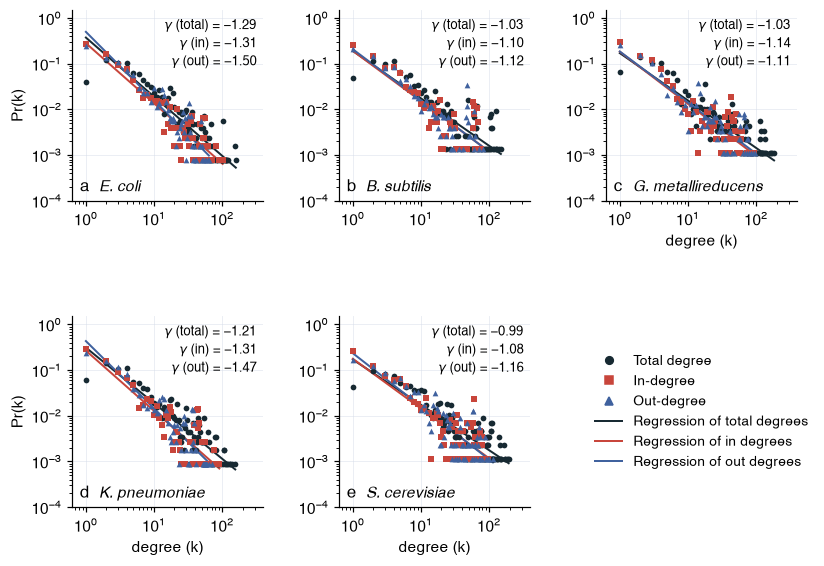

In [2]:
P.compare_with_original(sup_deg, FIG / "01_fig2_from_supplement.png", show_original=False)
plt.show()

In [3]:
rows = []
for k in data.KEYS:
    for kind in data.KIND_ORDER:
        g = R.ols(sup_deg[k][kind]); p = data.paper_gamma(k, kind)
        rows.append(dict(organism=data.NAME[k], degree=kind, ours=round(g, 4), truncated=float(trunc2(g)), rounded=round(g, 2),
                         paper=p, match_trunc=bool(trunc2(g) == p), match_round=bool(round(g, 2) == p)))
tab = pd.DataFrame(rows); tab.to_csv(RES / "01_supplement_gamma_vs_paper.csv", index=False)
print(f"matches the printed γ — truncated: {tab.match_trunc.sum()}/15   rounded: {tab.match_round.sum()}/15")
display(tab[~tab.match_trunc])

matches the printed γ — truncated: 14/15   rounded: 9/15


,organism,degree,ours,truncated,rounded,paper,match_trunc,match_round
1,E. coli,in,-1.316,-1.31,-1.32,-1.32,False,True


## 2 · Reproduction from raw data

Rebuilding the graphs from the BiGG models the paper cites. The paper only describes the conversion in words (currency metabolites removed, transport and exchange reactions
removed, arc B → C if a product of B is consumed by C), so the rules have to be inferred. This is the one graph builder (`metnet.graph.build_graph`) used for everything that follows.

### 2.1 Issues when it comes to full reproduction
**(i) Which BiGG release.** Based on the publication date we use the *older* BiGG models. They match the paper's Table 1 exactly; the newer release uses different IDs/reaction names and
differs slightly in content.

In [4]:
table1 = {"ecoli": (2583, 1805), "bsub": (1250, 990), "gmet": (1285, 1109), "kpneu": (2262, 1658), "scer": (1577, 1226)}  # paper Table 1: reactions, metabolites
rows = []
for k in data.KEYS:
    m = data.MODEL[k]
    ro, mo = data.count_sbml(data.OLD_BIGG / f"{m}.xml.gz")
    rn, mn = data.count_sbml(data.DATA / f"{m}.biggr.sbml.gz")
    ids = set(sup[k][0])
    new_ids = {i.removeprefix("R_").removeprefix(f"__{m}__") for i in
               __import__("metnet.data", fromlist=["x"]).read_model(m, data.DATA / f"{m}.biggr.sbml.gz", with_subsystems=False).rxns}
    rows.append({"model": f"{data.NAME[k]} ({m})", "Table 1 (rxn, met)": table1[k], "old BiGG (rxn, met)": (ro, mo), "new BiGG (rxn, met)": (rn, mn),
                 "old = Table 1": (ro, mo) == table1[k],
                 "supplement rxn IDs found: old": f"{len(ids & set(models[k].rxns))}/{len(ids)}", "new": f"{len(ids & new_ids)}/{len(ids)}"})
display(pd.DataFrame(rows).set_index("model"))

,"Table 1 (rxn, met)","old BiGG (rxn, met)","new BiGG (rxn, met)",old = Table 1,supplement rxn IDs found: old,new
model,,,,,,
E. coli (iJO1366),"(2583, 1805)","(2583, 1805)","(2583, 1805)",True,1247/1251,1199/1251
B. subtilis (iYO844),"(1250, 990)","(1250, 990)","(1250, 992)",True,748/748,659/748
G. metallireducens (iAF987),"(1285, 1109)","(1285, 1109)","(1285, 1109)",True,900/900,861/900
K. pneumoniae (iYL1228),"(2262, 1658)","(2262, 1658)","(2262, 1658)",True,1131/1137,1103/1137
S. cerevisiae (iMM904),"(1577, 1226)","(1577, 1226)","(1577, 1228)",True,881/881,830/881


**(ii) The currency-metabolite list is unclear** (the paper names only ATP, NAD and H₂O, and does not say whether a numeric cutoff was used). We recovered it from the supplement itself:
for every metabolite, build the arcs it would create between the supplement's own reactions and ask what fraction of them the supplement actually contains. Currency metabolites
create many arcs of which almost none are in the supplement; everything else is nearly all in. The split is clean — no cutoff is needed, the two groups do not overlap.

metabolites removed by the supplement (union over organisms): ['adp', 'amp', 'atp', 'co2', 'h', 'h2o', 'nad', 'nadh', 'nadp', 'nadph', 'nh4', 'o2', 'pi', 'ppi']
== our CURRENCY set: ['adp', 'amp', 'atp', 'co2', 'h', 'h2o', 'nad', 'nadh', 'nadp', 'nadph', 'nh4', 'o2', 'pi', 'ppi'] | identical: True


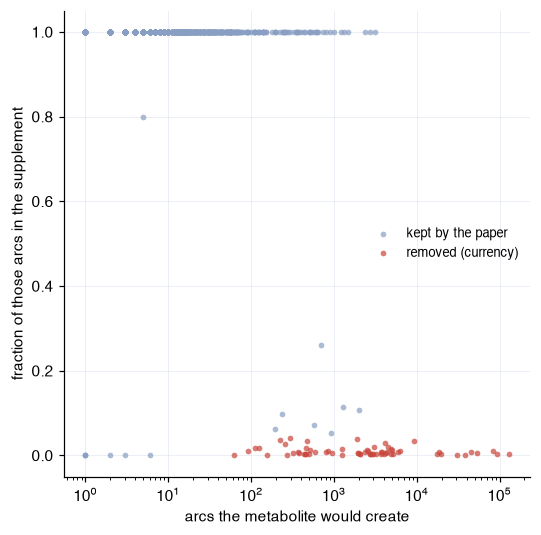

In [5]:
rows = []
for k in data.KEYS:
    M = models[k]; ids, A0 = sup[k]
    idx = {i: j for j, i in enumerate(ids)}
    found = [i for i in ids if i in M.rxns]
    S0 = {(a, b) for a, b in zip(*np.nonzero(A0))}
    prod, cons = {}, {}
    for i in found:
        r = M.rxns[i]
        for x in r.subs:
            cons.setdefault(x, set()).add(idx[i]);  r.reversible and prod.setdefault(x, set()).add(idx[i])
        for x in r.prods:
            prod.setdefault(x, set()).add(idx[i]);  r.reversible and cons.setdefault(x, set()).add(idx[i])
    for x in prod.keys() & cons.keys():
        arcs = {(a, b) for a in prod[x] for b in cons[x] if a != b}
        if arcs:
            rows.append(dict(organism=k, met=x, base=graph.base(x), n_arcs=len(arcs), frac_in_supp=len(arcs & S0) / len(arcs)))
audit = pd.DataFrame(rows)
audit["currency"] = (audit.n_arcs >= 20) & (audit.frac_in_supp <= 0.05)
found_cur = sorted(audit[audit.currency & (audit.organism != "scer") | (audit.currency & audit.met.str.endswith("_c"))].base.unique())
print("metabolites removed by the supplement (union over organisms):", found_cur)
print("== our CURRENCY set:", sorted(graph.CURRENCY), "| identical:", set(found_cur) == set(graph.CURRENCY))
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.grid(True, alpha=.5); ax.set_axisbelow(True)
for flag, c, lab in [(False, T.SOFT_BLUE, "kept by the paper"), (True, T.RED, "removed (currency)")]:
    s = audit[audit.currency == flag]; ax.scatter(s.n_arcs, s.frac_in_supp, s=14, color=c, alpha=.7, label=lab, linewidths=0)
ax.set(xscale="log", xlabel="arcs the metabolite would create", ylabel="fraction of those arcs in the supplement")
T.square(ax); ax.legend(loc="center right")
fig.savefig(FIG / "02_currency_audit.png"); plt.show()

**(iii) Regression method is not stated** — but OLS on log–log Pr(k) reproduces the published γ from the supplement (section 1), so the same fit is used for every raw-data result.

### 2.2 Which reactions are nodes?
The supplement has no exchange/boundary reactions and almost no periplasm- or extracellular-only reactions. The reaction filter (`reactions="reconstruction"`) is: drop exchange/demand/sink/biomass; drop reactions
whose BiGG subsystem is transport/exchange; drop reactions touching the extracellular space; drop periplasm-only reactions; in yeast keep only cytosol/mitochondria/ER; in *E. coli* also drop `…pp` ids;
drop reactions with no arcs. The first rules are directly supported by the supplement's node names; the last few are a best fit (documented in `metnet/graph.py`).

**Check:** given the supplement's own node set, does the rebuilt arc list match the supplement's?

In [6]:
rows = []
for k in data.KEYS:
    M = models[k]; ids, A0 = sup[k]; found = [i for i in ids if i in M.rxns]
    _, A = graph.build_graph(M, graph.RECONSTRUCTION, nodes=found)
    idx = {i: j for j, i in enumerate(ids)}; sel = [idx[i] for i in found]
    S0 = A0[np.ix_(sel, sel)].astype(bool); A = A.astype(bool)
    rows.append(dict(organism=data.NAME[k], supplement_nodes=len(ids), nodes_found_in_model=len(found), supplement_arcs=int(A0.sum()),
                     arcs_shared=int((A & S0).sum()), only_ours=int((A & ~S0).sum()), only_theirs=int((~A & S0).sum())))
chk = pd.DataFrame(rows).set_index("organism"); chk.to_csv(RES / "02_arc_check_given_supplement_nodes.csv"); display(chk)

,supplement_nodes,nodes_found_in_model,supplement_arcs,arcs_shared,only_ours,only_theirs
organism,,,,,,
E. coli,1251,1247,9099,9058,1,0
B. subtilis,748,748,6489,6489,0,0
G. metallireducens,900,900,8049,8049,1,0
K. pneumoniae,1137,1131,8084,7759,7,0
S. cerevisiae,881,881,10460,10460,0,0


### 2.3 Figure 2 rebuilt from the raw BiGG models

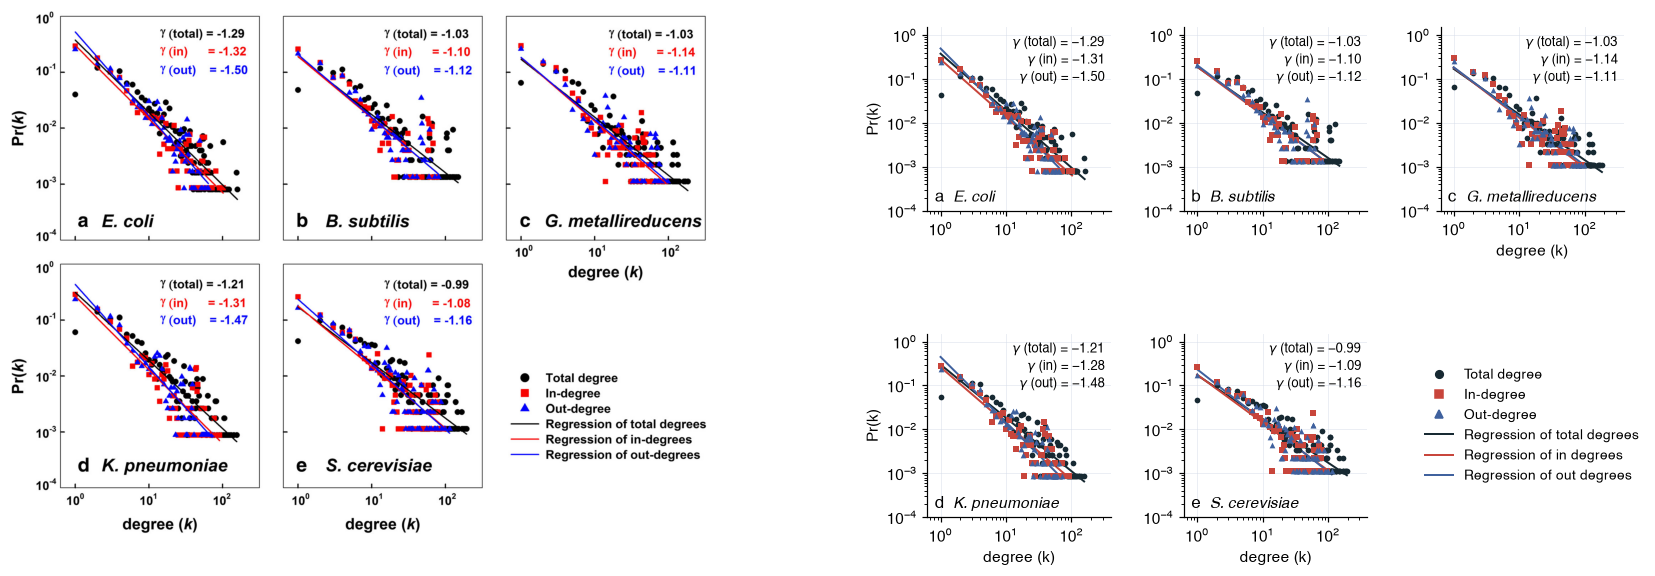

,nodes,nodes_paper,arcs,arcs_paper,γ total,γ total (paper),γ in,γ in (paper),γ out,γ out (paper)
organism,,,,,,,,,,
E. coli,1257,1251,9103,9099,-1.29,-1.29,-1.31,-1.32,-1.50,-1.50
B. subtilis,748,748,6489,6489,-1.03,-1.03,-1.10,-1.10,-1.12,-1.12
G. metallireducens,901,900,8050,8049,-1.03,-1.03,-1.14,-1.14,-1.11,-1.11
K. pneumoniae,1146,1137,8182,8084,-1.21,-1.21,-1.28,-1.31,-1.48,-1.47
S. cerevisiae,890,881,10466,10460,-0.99,-0.99,-1.09,-1.08,-1.16,-1.16


γ identical to the paper: 11/15 (the rest differ by 0.01-0.03)


In [7]:
rebuilt, raw_deg = {}, {}
for k in data.KEYS:
    ids, A = graph.build_graph(models[k], graph.RECONSTRUCTION)
    rebuilt[k] = (ids, A); raw_deg[k] = graph.degrees(A)
P.compare_with_original(raw_deg, FIG / "03_fig2_from_raw_data.png")
plt.show()
rows = []
for k in data.KEYS:
    n, a = len(rebuilt[k][0]), int(rebuilt[k][1].sum()); pn, pa = data.PAPER_COUNTS[k]
    row = dict(organism=data.NAME[k], nodes=n, nodes_paper=pn, arcs=a, arcs_paper=pa)
    for kind in data.KIND_ORDER:
        row[f"γ {kind}"] = float(trunc2(R.ols(raw_deg[k][kind]))); row[f"γ {kind} (paper)"] = data.paper_gamma(k, kind)
    rows.append(row)
raw_tab = pd.DataFrame(rows).set_index("organism"); raw_tab.to_csv(RES / "03_raw_rebuild_vs_paper.csv")
display(raw_tab)
same = sum(raw_tab[f"γ {kd}"].iloc[i] == raw_tab[f"γ {kd} (paper)"].iloc[i] for i in range(5) for kd in data.KIND_ORDER)
print(f"γ identical to the paper: {same}/15 (the rest differ by 0.01-0.03)")

Node/arc counts are within ~0.5 % for four organisms; *K. pneumoniae* is furthest off (the paper's list uses old reaction IDs that no longer exist in the model, so it could not be
checked reaction by reaction). The remaining differences are individual reactions the paper keeps or drops that we cannot distinguish from the model alone.

## 3 · Sensitivity 1 — modifying metabolite filtering

### 3.1 Paper vs different filtering steps
Two switches in the same graph builder, plus the paper-matching node rule:

| Tier | Currency metabolites | Reactions (nodes) |
|---|---|---|
| Unfiltered | all allowed to make links | every reaction in the model |
| Currency filtered | removed | every reaction |
| Compartment filtered | allowed | no boundary reactions; cytosol only (+ mitochondria in yeast) |
| Fully filtered (simple) | removed | as above |
| **Fully filtered (reconstruction)** — ours | removed | the paper-matching rules of §2.2 |

Reactions with no arc are not nodes, in every tier. All fits use the same log–log OLS.

In [8]:
tier_deg, tier_rows = {}, []
for k in data.KEYS:
    tier_deg[k] = {}
    for rules in graph.TIERS:
        ids, A = graph.build_graph(models[k], rules)
        D = graph.degrees(A); tier_deg[k][rules.name] = D
        tier_rows.append(dict(organism=data.NAME[k], tier=rules.name, nodes=len(ids), arcs=int(A.sum()),
                              **{f"γ {kd}": R.ols(D[kd]) for kd in data.KIND_ORDER}))
tiers = pd.DataFrame(tier_rows); tiers.to_csv(RES / "04_filtering_tiers.csv", index=False)

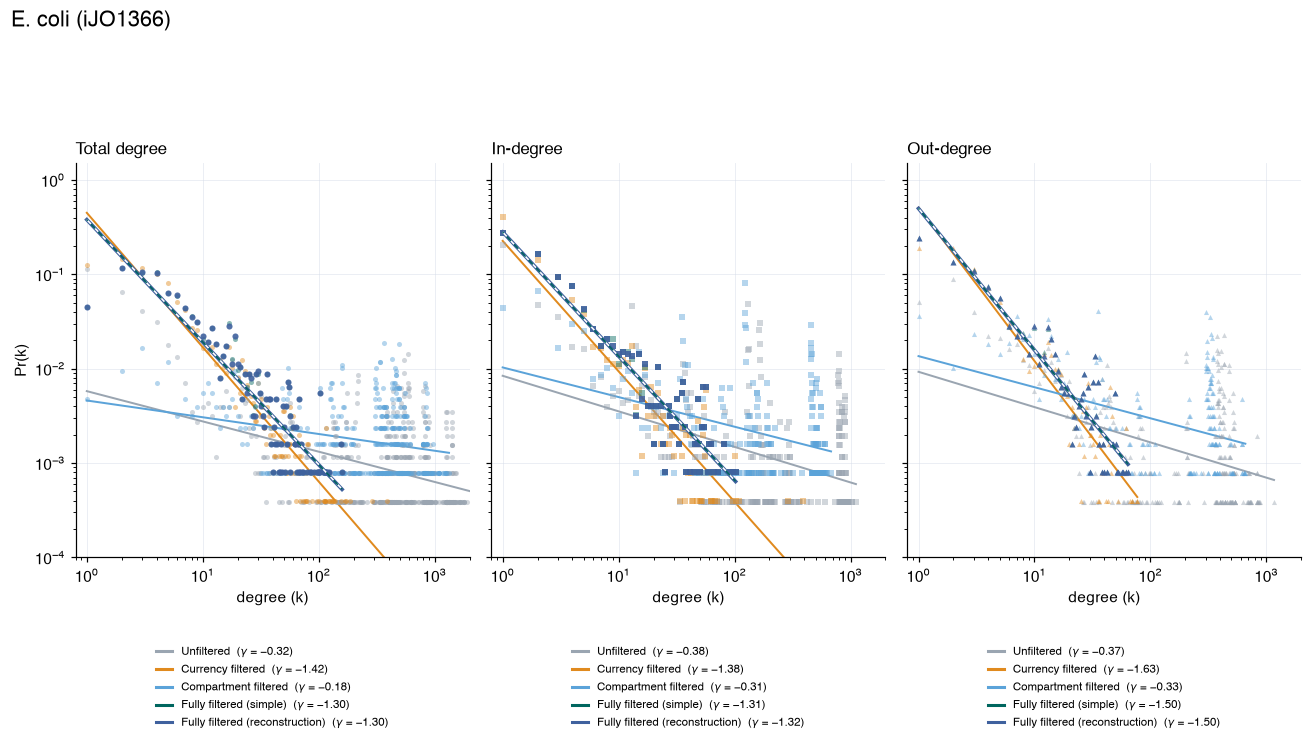

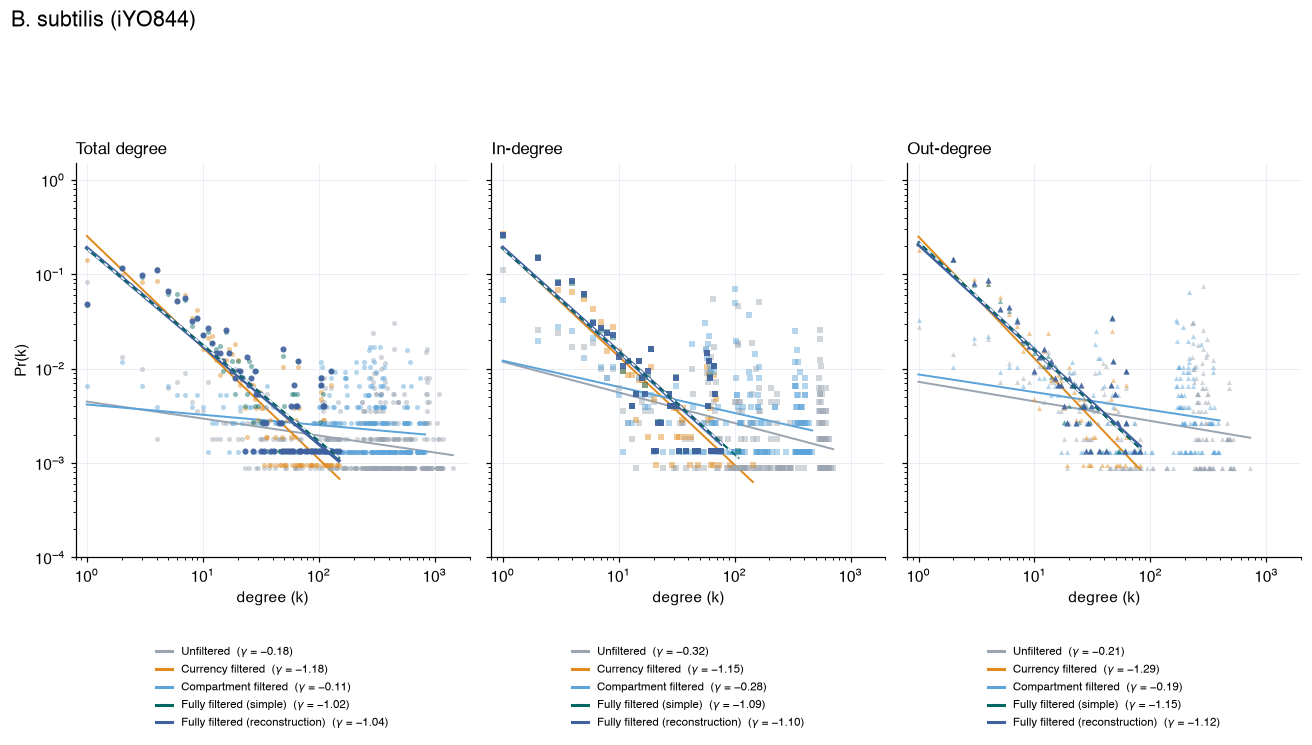

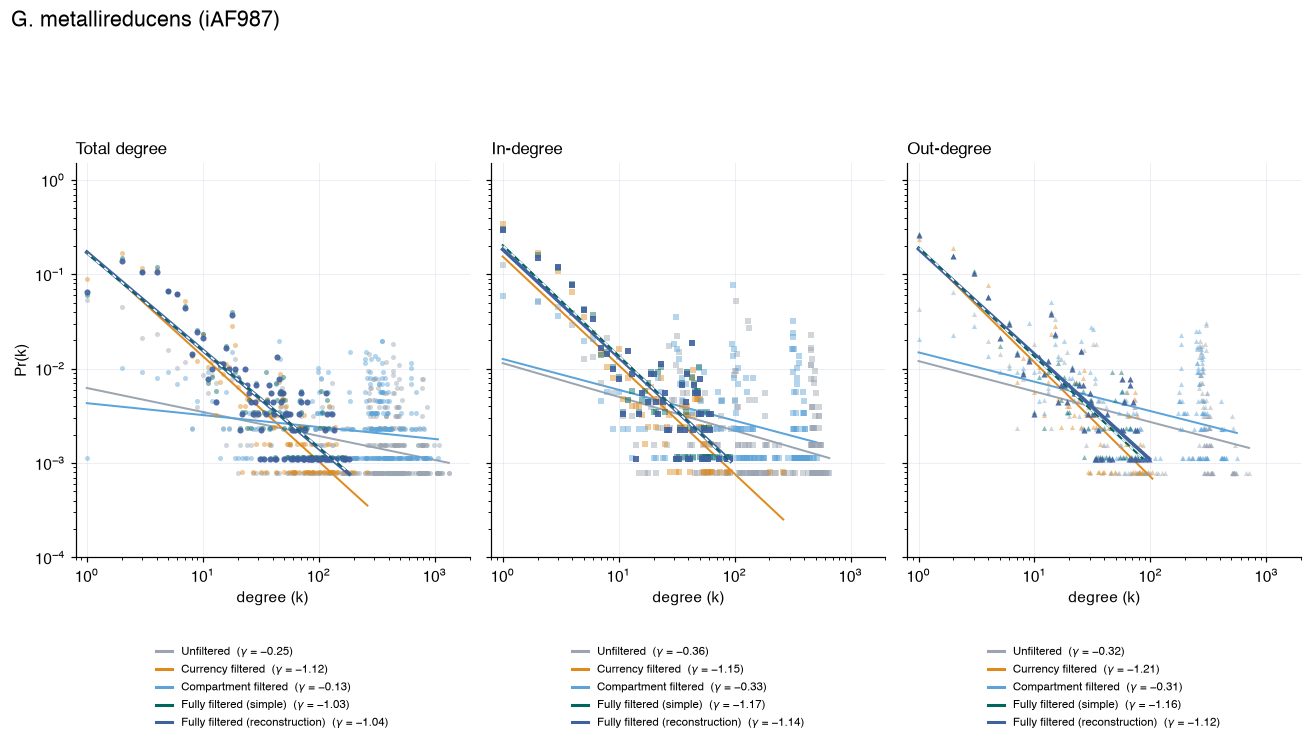

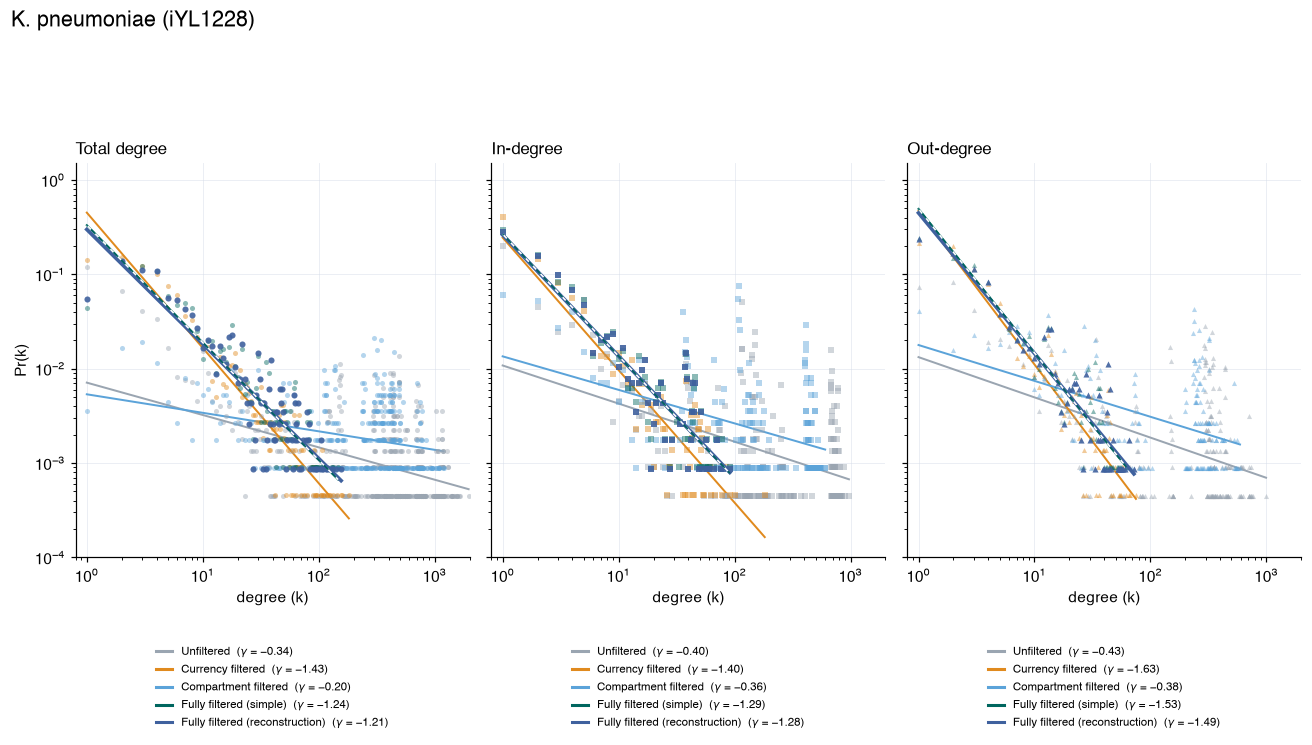

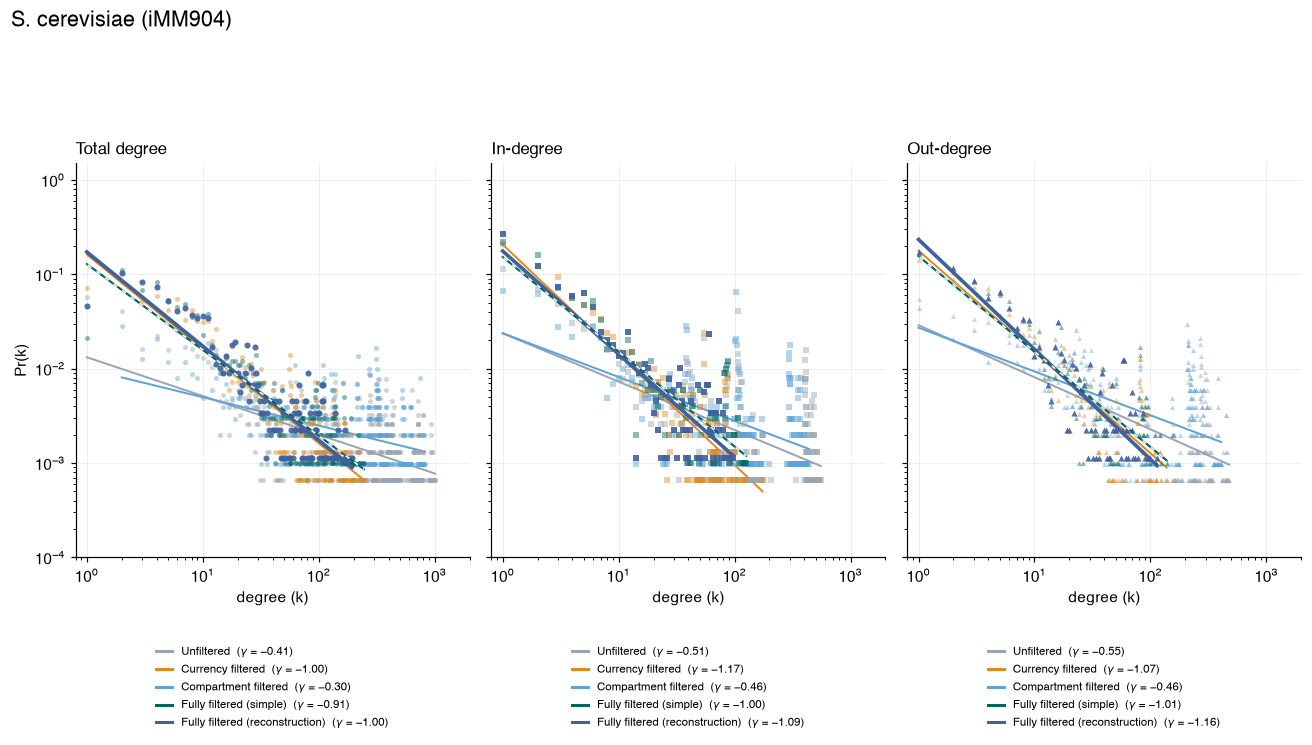

In [9]:
for k in data.KEYS:
    P.tier_figure(k, tier_deg[k], FIG / f"04_filtering_tiers_{k}.png")
    plt.show()

In [10]:
display(tiers.round(2).set_index(["organism", "tier"]))

nodes    arcs  γ total  γ in  γ out
organism           tier                                                                
E. coli            Unfiltered                        2563  439523    -0.32 -0.38  -0.37
                   Currency filtered                 2528   14583    -1.42 -1.38  -1.63
                   Compartment filtered              1272  209186    -0.18 -0.31  -0.33
                   Fully filtered (simple)           1253    9086    -1.30 -1.31  -1.50
                   Fully filtered (reconstruction)   1257    9103    -1.30 -1.32  -1.50
B. subtilis        Unfiltered                        1119  194154    -0.18 -0.32  -0.21
                   Currency filtered                 1048    7766    -1.18 -1.15  -1.29
                   Compartment filtered               762  102413    -0.11 -0.28  -0.19
                   Fully filtered (simple)            742    6559    -1.02 -1.09  -1.15
                   Fully filtered (reconstruction)    748    6489    -1.04 -1.10  -1.12
G. metallireducens Unfiltered                        1273  178902    -0.25 -0.36  -0.32
                   Currency filtered                 1244    9449    -1.12 -1.15  -1.21
                   Compartment filtered               875  116795    -0.13 -0.33  -0.31
                   Fully filtered (simple)            860    7193    -1.03 -1.17  -1.16
                   Fully filtered (reconstruction)    901    8050    -1.04 -1.14  -1.12
K. pneumoniae      Unfiltered                        2220  309299    -0.34 -0.40  -0.43
                   Currency filtered                 2178   11506    -1.43 -1.40  -1.63
                   Compartment filtered              1137  156322    -0.20 -0.36  -0.38
                   Fully filtered (simple)           1114    7738    -1.24 -1.29  -1.53
                   Fully filtered (reconstruction)   1146    8182    -1.21 -1.28  -1.49
S. cerevisiae      Unfiltered                        1530  164003    -0.41 -0.51  -0.55
                   Currency filtered                 1517   23435    -1.00 -1.17  -1.07
                   Compartment filtered              1016  107407    -0.30 -0.46  -0.46
                   Fully filtered (simple)           1001   14899    -0.91 -1.00  -1.01
                   Fully filtered (reconstruction)    890   10466    -1.00 -1.09  -1.16

### 3.2 Test 1 · What does adding currency metabolites do?

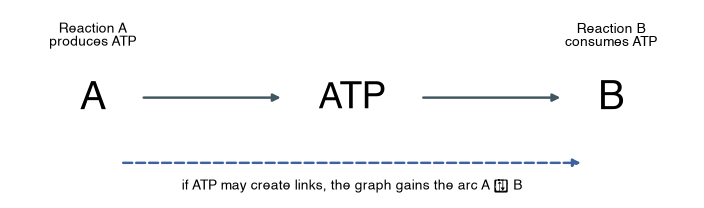

In [11]:
P.currency_schematic(FIG / "05_currency_schematic.png"); plt.show()

**Compare two versions of *E. coli*.** Same reactions, same directions, same fit — only the currency switch changes. (1) Exclude the currency list and build links from the remaining
metabolites; (2) allow the currency list to create links; (3) compare the distributions and γ. Our currency list is a documented approximation of the paper's filtering (§2.1).

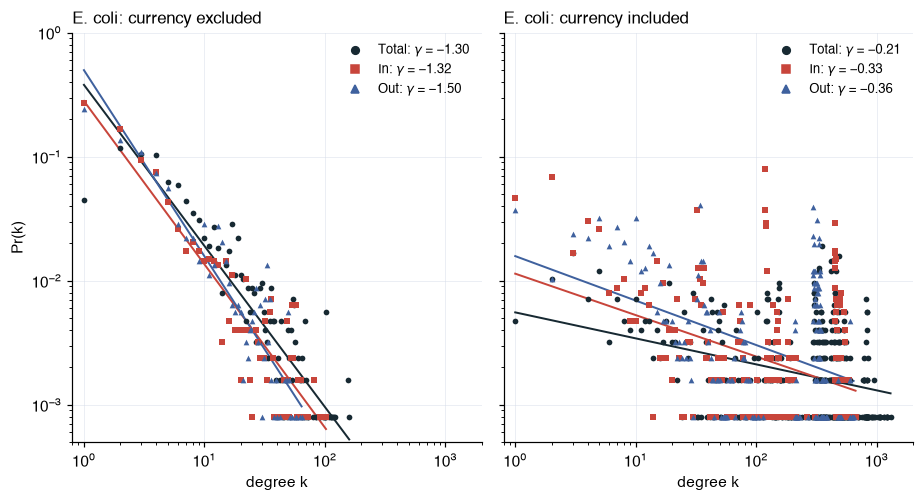

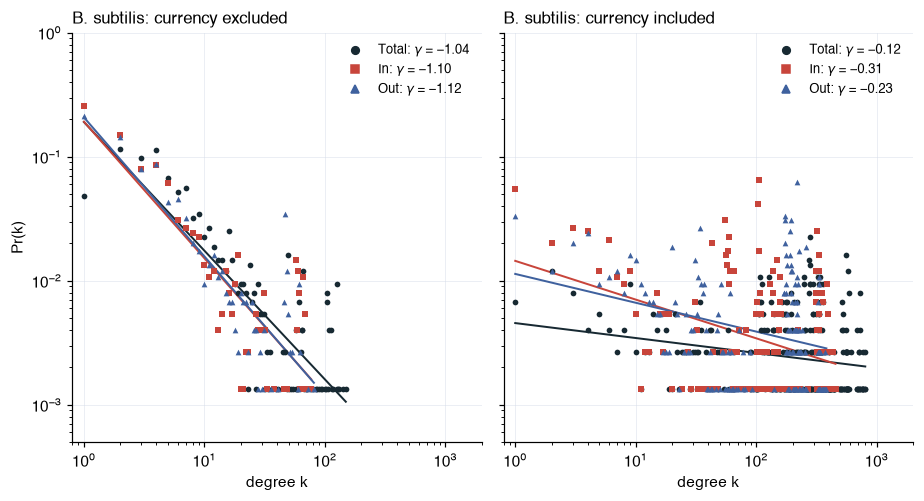

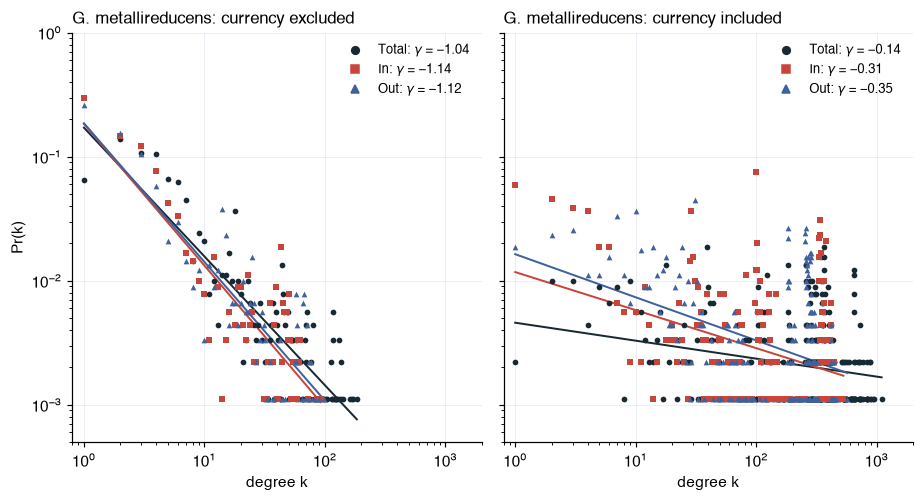

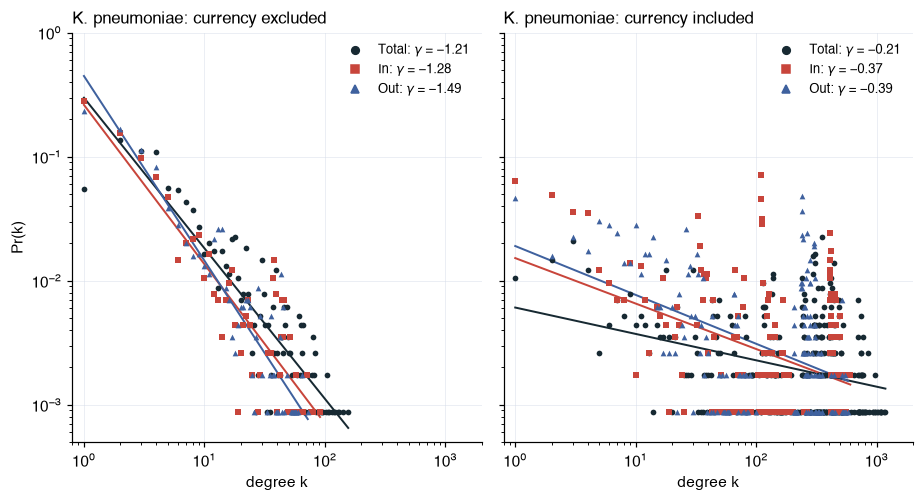

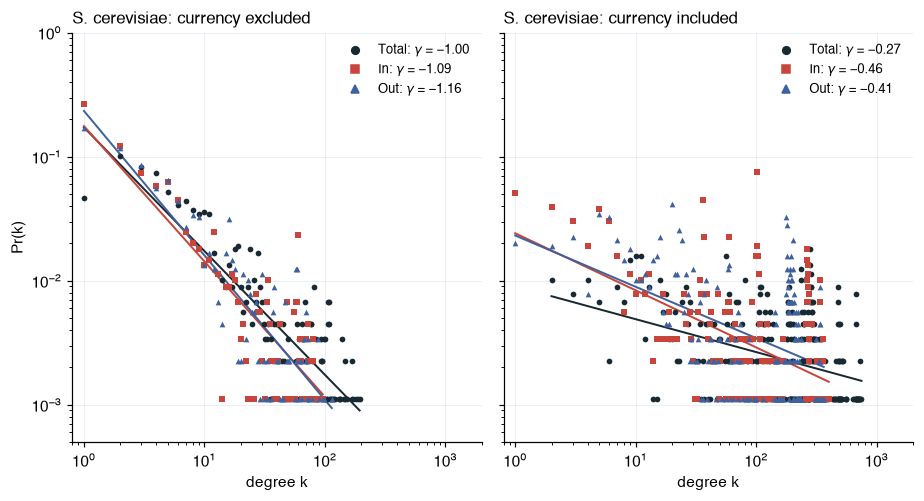

E. coli                         B. subtilis                   G. metallireducens                       K. pneumoniae  \
                    Currency excluded Currency included Currency excluded Currency included  Currency excluded Currency included Currency excluded   
Reactions                     1257.00           1257.00            748.00            748.00             901.00            901.00           1146.00   
Directed links                9103.00         199898.00           6489.00          99167.00            8050.00         124094.00           8182.00   
Median total degree              7.00            331.00              7.00            258.00               6.00            285.00              6.00   
Total-degree γ                  -1.30             -0.21             -1.04             -0.12              -1.04             -0.14             -1.21   
In-degree γ                     -1.32             -0.33             -1.10             -0.31              -1.14             -0.31             -1.28   
Out-degree γ                    -1.50             -0.36             -1.12             -0.23              -1.12             -0.35             -1.49   

                                          S. cerevisiae                    
                    Currency included Currency excluded Currency included  
Reactions                     1146.00            890.00            890.00  
Directed links              155372.00          10466.00          85937.00  
Median total degree            296.00              9.00            181.00  
Total-degree γ                  -0.21             -1.00             -0.27  
In-degree γ                     -0.37             -1.09             -0.46  
Out-degree γ                    -0.39             -1.16             -0.41

**In *E. coli*, directed links increase from 9,103 to 199,898.** Common metabolites create many more connections between reactions, and the fitted result depends strongly on currency filtering (total γ -1.30 → -0.21).

In [12]:
t1_all = {}
for k in data.KEYS:
    ids_k, A_k = rebuilt[k]                                  # fixed node set = the reconstruction
    _, A_exc_k = graph.build_graph(models[k], graph.RECONSTRUCTION, nodes=ids_k)
    _, A_inc_k = graph.build_graph(models[k], graph.Rules("currency allowed", currency=False), nodes=ids_k)
    D_exc_k, D_inc_k = graph.degrees(A_exc_k), graph.degrees(A_inc_k)
    assert (A_exc_k == A_k).all() and (A_inc_k >= A_exc_k).all()
    fig, (g_exc_k, g_inc_k) = P.two_panel(D_exc_k, D_inc_k, (f"{data.NAME[k]}: currency excluded", f"{data.NAME[k]}: currency included"),
                                          path=FIG / f"06_test1_currency_{k}.png")
    plt.show()
    t1_all[k] = (A_exc_k, A_inc_k, g_exc_k, g_inc_k)
    for lab, A_, D_, g_ in [("Currency excluded", A_exc_k, D_exc_k, g_exc_k), ("Currency included", A_inc_k, D_inc_k, g_inc_k)]:
        t1_all[(k, lab)] = {"Reactions": len(ids_k), "Directed links": int(A_.sum()), "Median total degree": np.median(D_["total"]),
                            "Total-degree γ": g_["total"], "In-degree γ": g_["in"], "Out-degree γ": g_["out"]}
t1 = pd.DataFrame({(data.NAME[k], lab): t1_all[(k, lab)] for k in data.KEYS for lab in ("Currency excluded", "Currency included")})
t1.to_csv(RES / "05_test1_currency_all.csv"); display(t1.round(2))
A_exc, A_inc, g_exc, g_inc = t1_all["ecoli"]                 # E. coli, used in the summary text below
display(Markdown(f"**In *E. coli*, directed links increase from {int(A_exc.sum()):,} to {int(A_inc.sum()):,}.** Common metabolites create many more connections between reactions, "
                 f"and the fitted result depends strongly on currency filtering (total γ {g_exc['total']:.2f} → {g_inc['total']:.2f})."))

### 3.3 Test 2 · Fit different parts of the same distribution
Same currency-excluded graph (each organism); fit (1) every observed positive degree (k ≥ 1) and (2) only degrees k ≥ 10 (an exploratory cutoff). Both panels show all points.

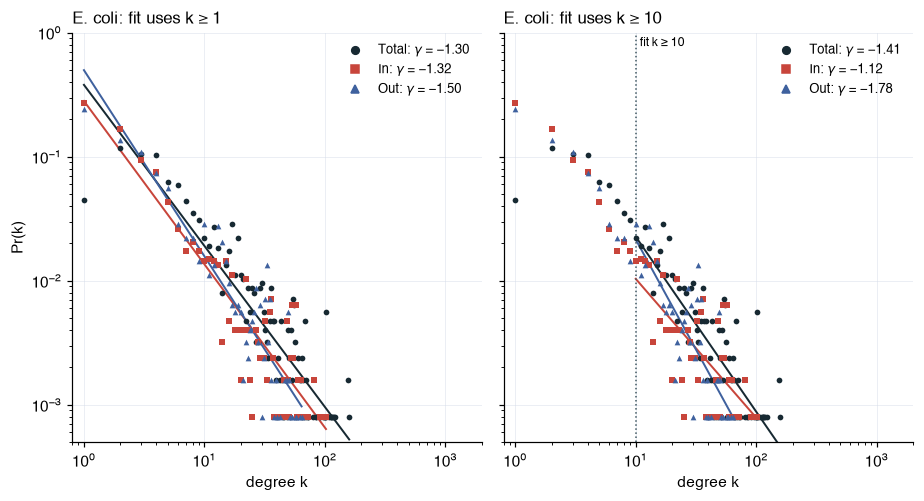

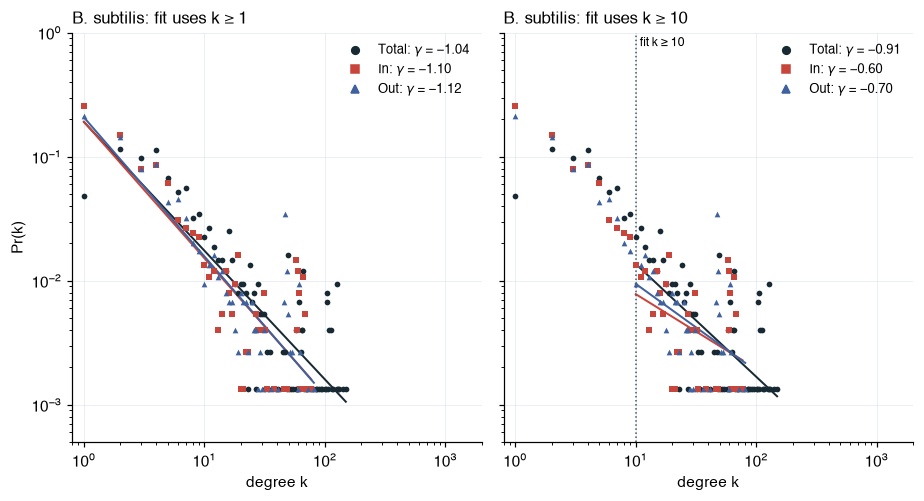

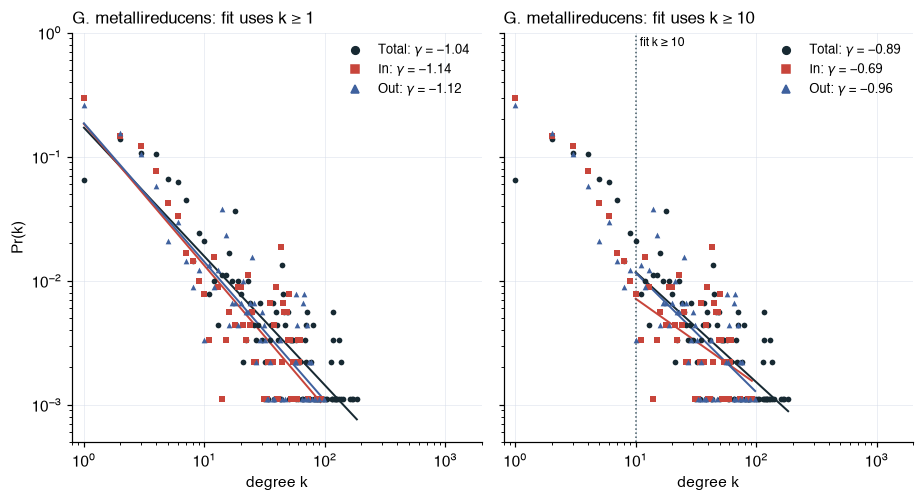

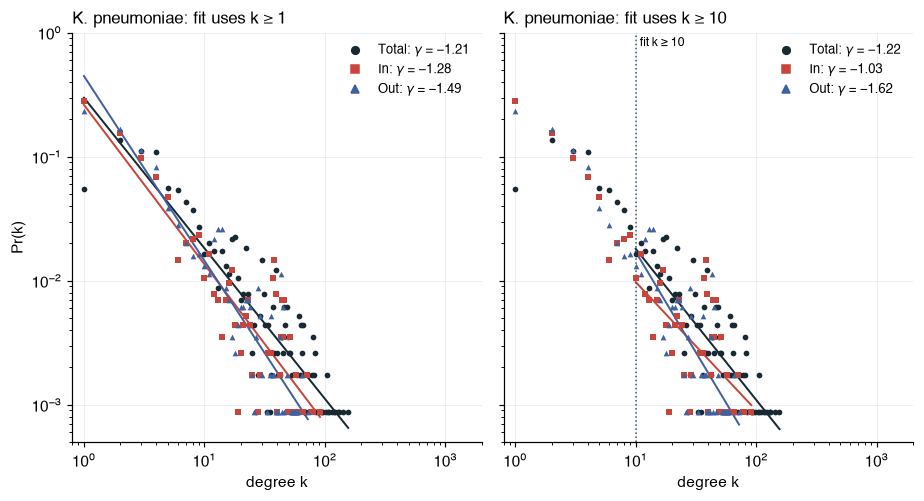

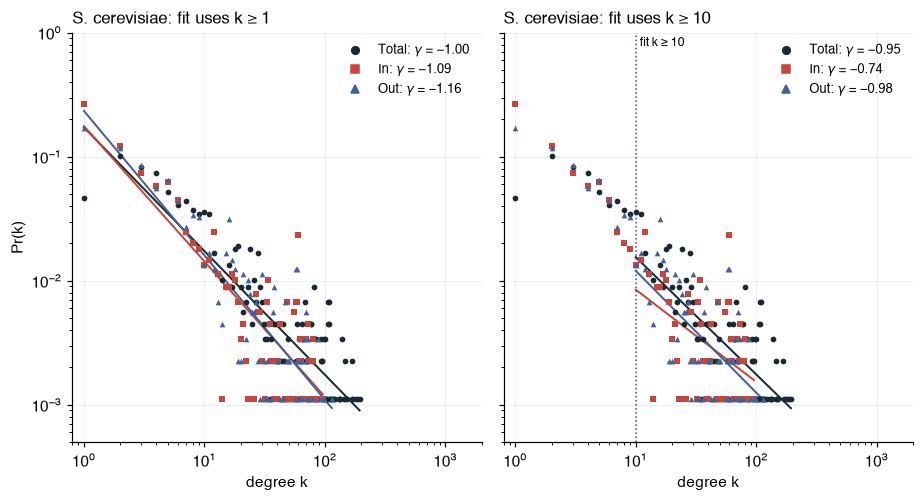

E. coli        B. subtilis        G. metallireducens        K. pneumoniae        S. cerevisiae       
          k ≥ 1 k ≥ 10       k ≥ 1 k ≥ 10              k ≥ 1 k ≥ 10         k ≥ 1 k ≥ 10         k ≥ 1 k ≥ 10
total γ   -1.30  -1.41       -1.04  -0.91              -1.04  -0.89         -1.21  -1.22         -1.00  -0.95
in γ      -1.32  -1.12       -1.10  -0.60              -1.14  -0.69         -1.28  -1.03         -1.09  -0.74
out γ     -1.50  -1.78       -1.12  -0.70              -1.12  -0.96         -1.49  -1.62         -1.16  -0.98

*E. coli*: total γ -1.30 → -1.41; **in γ -1.32 → -1.12**; out γ -1.50 → -1.78. Fewer degree values enter the k ≥ 10 fit.

In [13]:
t2_all = {}
for k in data.KEYS:
    D = raw_deg[k]
    fig, (g1_k, g10_k) = P.two_panel(D, D, (f"{data.NAME[k]}: fit uses k ≥ 1", f"{data.NAME[k]}: fit uses k ≥ 10"), kmins=(1, 10),
                                     path=FIG / f"07_test2_fit_range_{k}.png")
    plt.show()
    t2_all[k] = (g1_k, g10_k)
t2 = pd.DataFrame({(data.NAME[k], lab): g for k in data.KEYS for lab, g in zip(("k ≥ 1", "k ≥ 10"), t2_all[k])}).rename(index=lambda s: f"{s} γ")
t2.to_csv(RES / "06_test2_fit_range_all.csv"); display(t2.round(2))
g1, g10 = t2_all["ecoli"]                                    # E. coli, used in the summary text below
display(Markdown(f"*E. coli*: total γ {g1['total']:.2f} → {g10['total']:.2f}; **in γ {g1['in']:.2f} → {g10['in']:.2f}**; out γ {g1['out']:.2f} → {g10['out']:.2f}. Fewer degree values enter the k ≥ 10 fit."))

In [14]:
tt = tiers[tiers.organism == "E. coli"].set_index("tier")
display(Markdown(f'''
### What do the sensitivity tests tell us?
- **Currency filtering changes the network.** Including the currency list adds links ({int(A_exc.sum()):,} → {int(A_inc.sum()):,} in *E. coli*) and produces much flatter fitted slopes
  (total γ {g_exc['total']:.2f} → {g_inc['total']:.2f}). Across filtering tiers (*E. coli*, total γ): unfiltered {tt.loc['Unfiltered','γ total']:.2f}; currency filter alone {tt.loc['Currency filtered','γ total']:.2f};
  compartment/boundary filter alone {tt.loc['Compartment filtered','γ total']:.2f}; both (reconstruction) {tt.loc['Fully filtered (reconstruction)','γ total']:.2f}. Only the combination recovers the paper's slope.
- **The fitting range changes the estimate.** Total γ moves least ({g1['total']:.2f} → {g10['total']:.2f}); in- and out-degree γ move more ({g1['in']:.2f} → {g10['in']:.2f}, {g1['out']:.2f} → {g10['out']:.2f}).
- **Our comparisons show dependence on analysis choices. Assessing power-law fit requires additional analysis** → section 4.
'''))


### What do the sensitivity tests tell us?
- **Currency filtering changes the network.** Including the currency list adds links (9,103 → 199,898 in *E. coli*) and produces much flatter fitted slopes
  (total γ -1.30 → -0.21). Across filtering tiers (*E. coli*, total γ): unfiltered -0.32; currency filter alone -1.42;
  compartment/boundary filter alone -0.18; both (reconstruction) -1.30. Only the combination recovers the paper's slope.
- **The fitting range changes the estimate.** Total γ moves least (-1.30 → -1.41); in- and out-degree γ move more (-1.32 → -1.12, -1.50 → -1.78).
- **Our comparisons show dependence on analysis choices. Assessing power-law fit requires additional analysis** → section 4.


## 4 · Sensitivity 2 — changing the method of power-law fitting

The paper never says how γ was fitted. Here the *same* published graphs (the supplement's degree sequences) are fitted by every estimator we tried, all in one module (`metnet.regression`):

| Method | What it does |
|---|---|
| log-log OLS | **the paper's method** — unweighted OLS of log Pr(k) on log k, one point per observed k |
| log-log WLS (weight = count) | same, each k weighted by the number of nodes that have it |
| log-log OLS (k seen in ≥ 2 nodes) | same, dropping degrees seen in a single node (the flat 1/N floor) |
| log-log OLS on cumulative | OLS on P(K ≥ k); γ = slope − 1 |
| MLE (kmin = 1) | discrete power-law maximum likelihood over all degrees |
| MLE (kmin by KS) | maximum likelihood above the kmin that minimises the KS distance (Clauset et al.) |
| log-log OLS (log-binned) *(extra)* | OLS on log-binned densities |
| MLE bounded (= Poisson GLM) *(extra)* | power-law MLE on the observed support; identical to a Poisson regression over all degree bins |

The semi-log (`log-linear`, an exponential) and `linear` regressions have no γ and appear only as curves in 4.2.

In [15]:
rows = []
for k in data.KEYS:
    for kind in data.KIND_ORDER:
        for m, g in R.gamma_table(sup_deg[k][kind]).items():
            rows.append(dict(organism=k, kind=kind, method=m, gamma=g, paper=data.paper_gamma(k, kind)))
gt = pd.DataFrame(rows); gt.to_csv(RES / "07_gamma_by_method.csv", index=False)
wide = gt.pivot_table(index=["organism", "kind"], columns="method", values="gamma")[list(R.ESTIMATORS)]
wide.insert(0, "paper", gt.drop_duplicates(["organism", "kind"]).set_index(["organism", "kind"]).paper)
display(wide.rename(index=data.NAME, level=0).round(2))

method                    paper  log-log OLS  log-log WLS (weight = count)  log-log OLS (k seen in >= 2 nodes)  log-log OLS on cumulative  MLE (kmin = 1)  \
organism           kind                                                                                                                                     
B. subtilis        in     -1.10        -1.10                         -1.04                               -0.89                      -2.12           -1.55   
                   out    -1.12        -1.12                         -0.95                               -0.99                      -2.18           -1.51   
                   total  -1.03        -1.04                         -0.90                               -0.80                      -2.05           -1.39   
E. coli            in     -1.32        -1.32                         -1.24                               -1.22                      -2.35           -1.58   
                   out    -1.50        -1.50                         -1.14                               -1.31                      -2.56           -1.54   
                   total  -1.29        -1.29                         -1.02                               -1.10                      -2.35           -1.39   
G. metallireducens in     -1.14        -1.14                         -1.16                               -1.02                      -2.22           -1.56   
                   out    -1.11        -1.12                         -1.11                               -0.96                      -2.24           -1.53   
                   total  -1.03        -1.04                         -1.01                               -0.90                      -2.15           -1.39   
K. pneumoniae      in     -1.31        -1.32                         -1.18                               -1.10                      -2.35           -1.59   
                   out    -1.47        -1.47                         -1.13                               -1.25                      -2.54           -1.55   
                   total  -1.21        -1.22                         -1.01                               -1.07                      -2.36           -1.40   
S. cerevisiae      in     -1.08        -1.09                         -1.04                               -0.98                      -2.16           -1.49   
                   out    -1.16        -1.16                         -0.96                               -1.02                      -2.25           -1.45   
                   total  -0.99        -0.99                         -0.90                               -0.86                      -2.11           -1.35   

method                    MLE (kmin by KS)  log-log OLS (log-binned)  MLE bounded (= Poisson GLM)  
organism           kind                                                                            
B. subtilis        in                -1.89                     -1.49                        -1.30  
                   out               -1.87                     -1.70                        -1.25  
                   total             -1.78                     -1.35                        -1.07  
E. coli            in                -1.76                     -1.68                        -1.40  
                   out               -1.86                     -1.93                        -1.26  
                   total             -2.37                     -1.45                        -1.09  
G. metallireducens in                -6.91                     -1.67                        -1.36  
                   out               -2.43                     -1.45                        -1.32  
                   total             -1.67                     -1.27                        -1.12  
K. pneumoniae      in                -1.75                     -1.67                        -1.40  
                   out               -1.75                     -1.83                        -1.30  
                   total      

### 4.1 Using different methods of fitting the power law changes γ
Dashed lines are the published values. Every method that is not the paper's OLS moves γ — by up to ~1 (cumulative OLS, KS-kmin MLE) — and the in/out/total ordering is not stable across methods.

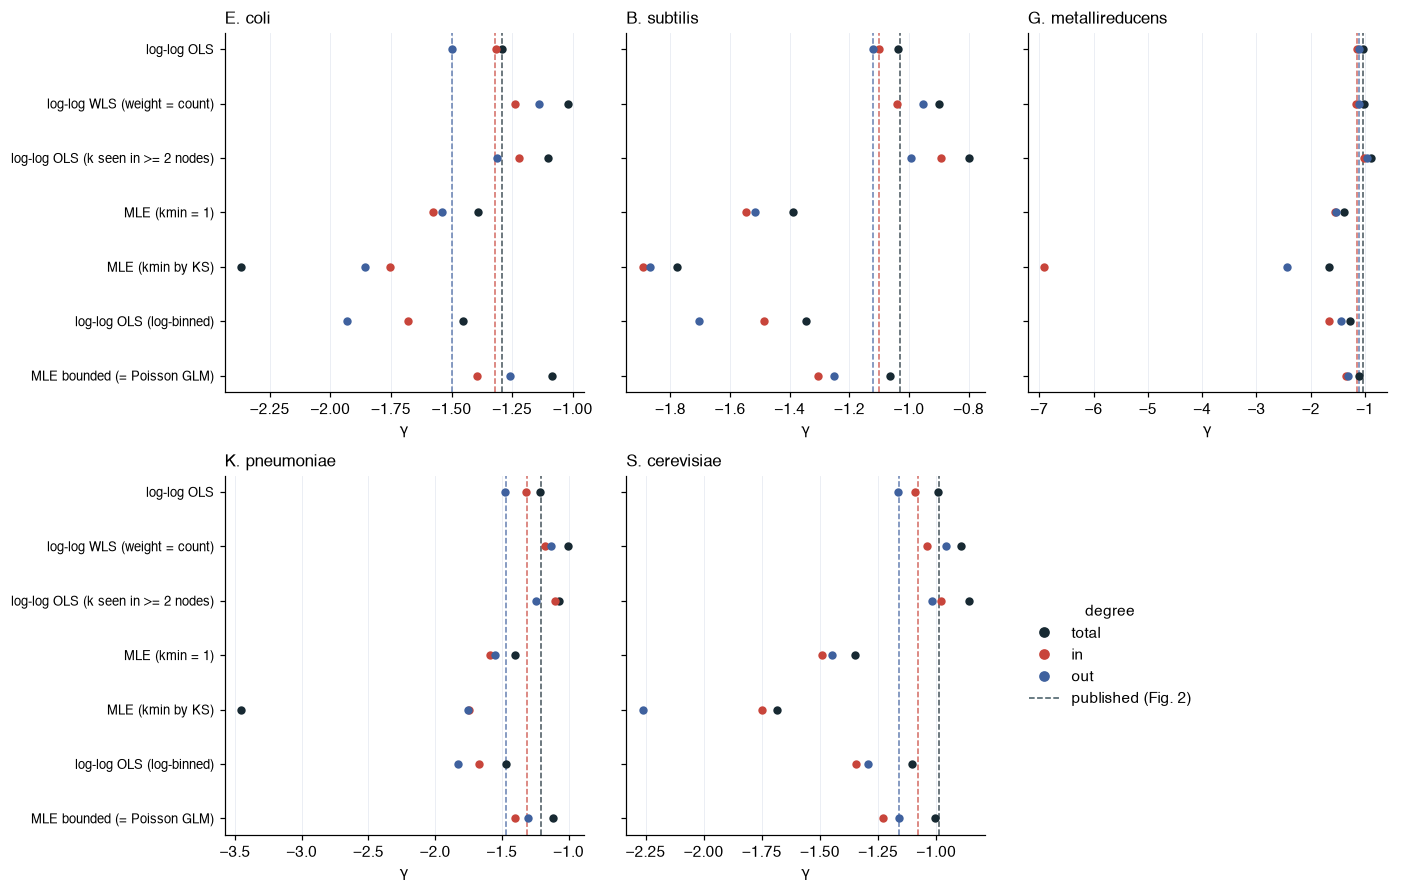

In [16]:
P.gamma_by_method(gt, FIG / "08_gamma_by_method.png"); plt.show()

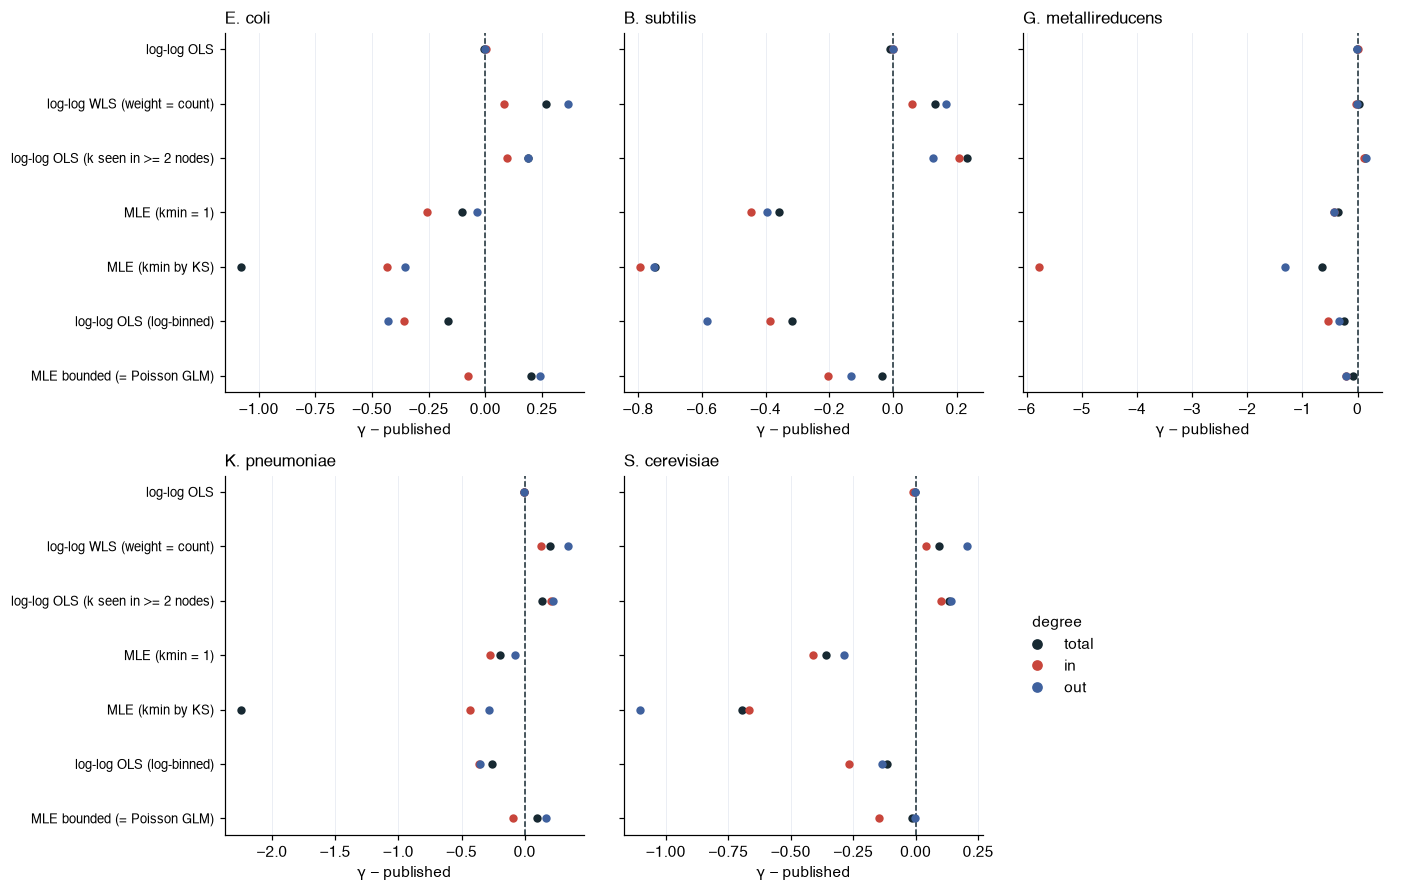

In [17]:
P.gamma_by_method(gt, FIG / "09_gamma_minus_published.png", delta=True); plt.show()

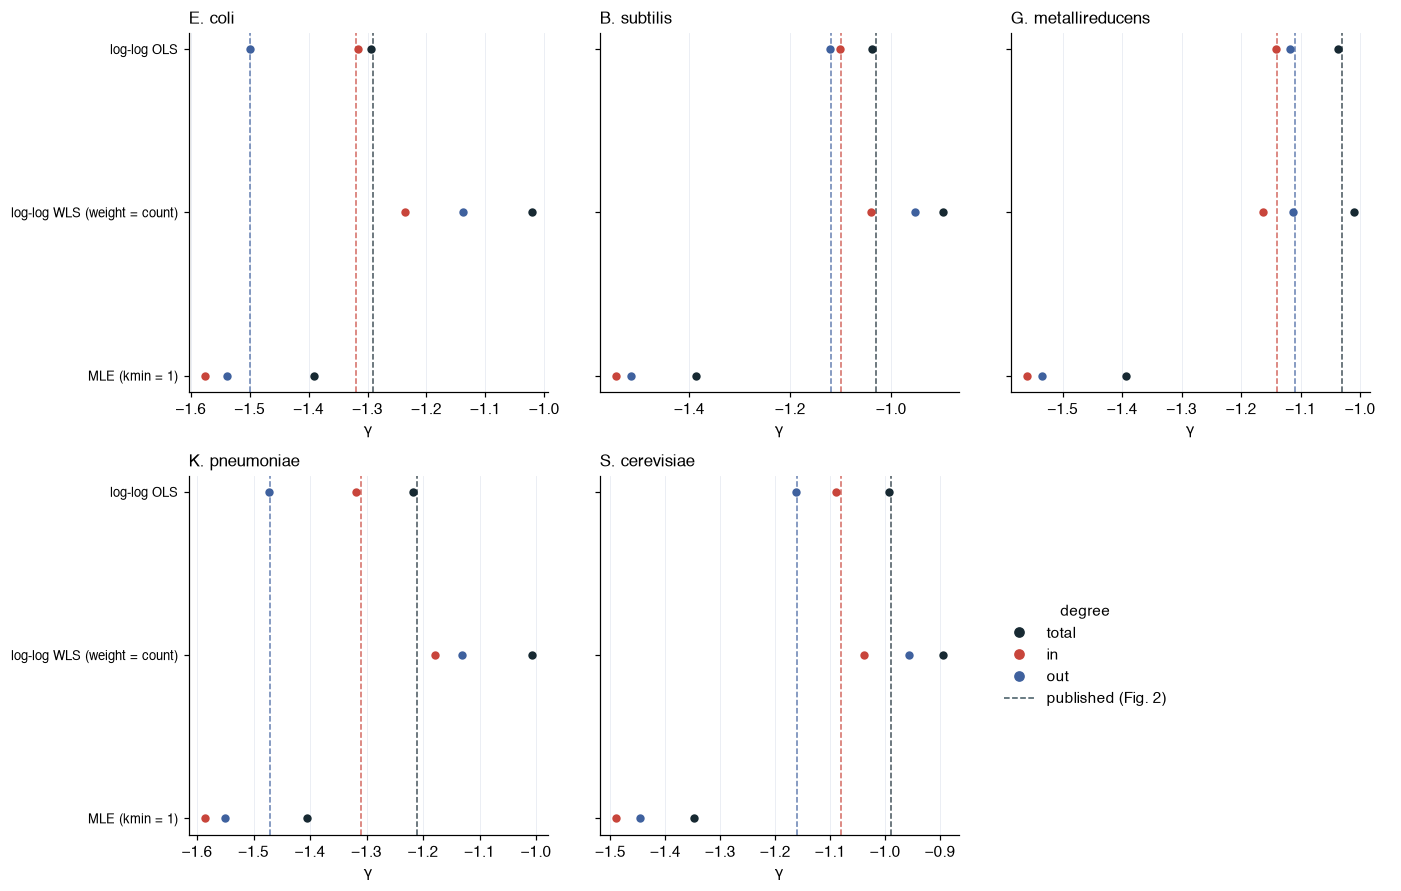

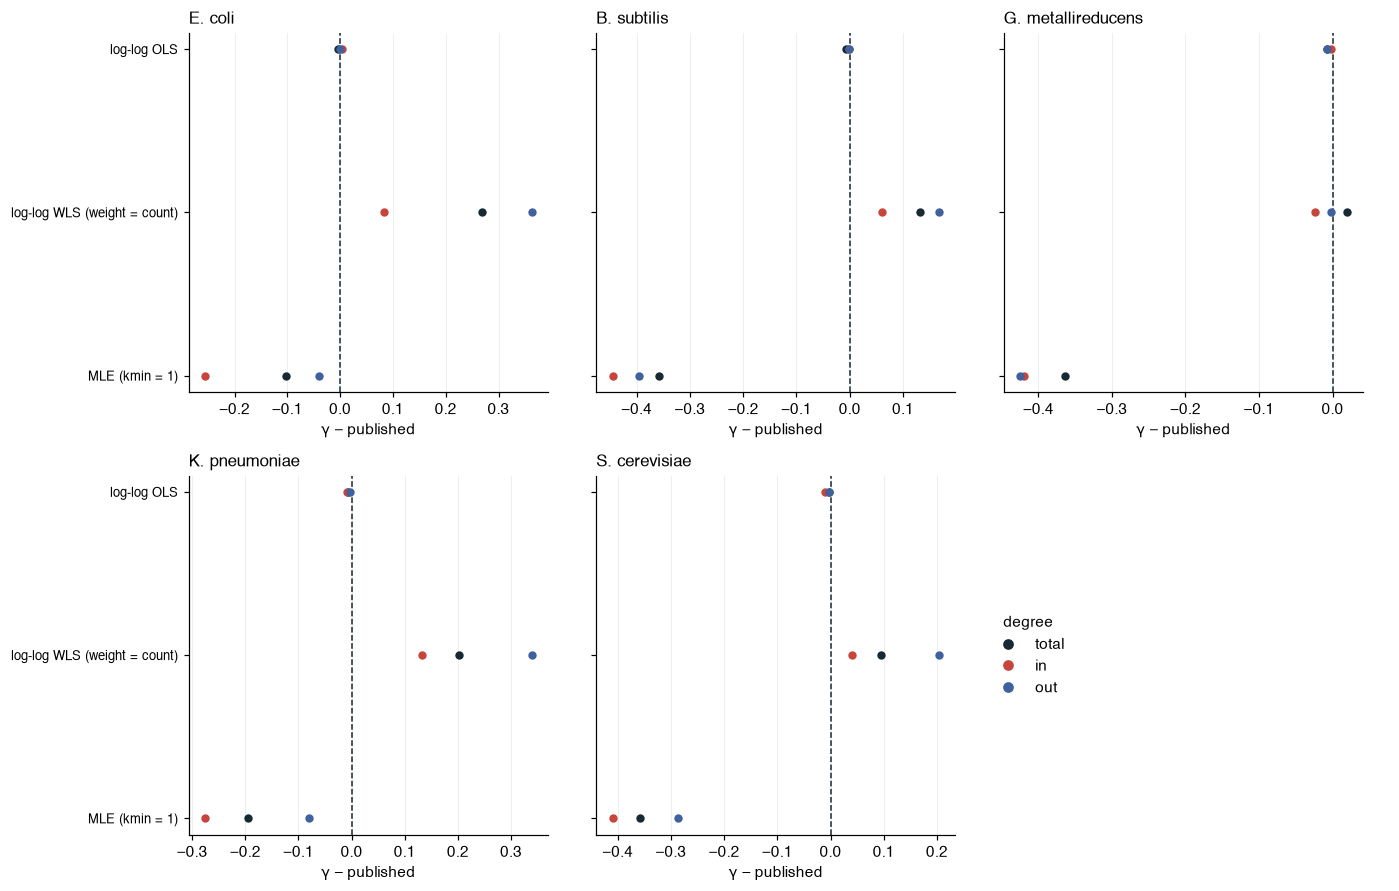

In [18]:
P.gamma_by_method(gt, FIG / "08_gamma_by_method_core.png", methods=P.CORE_METHODS); plt.show()
P.gamma_by_method(gt, FIG / "09_gamma_minus_published_core.png", delta=True, methods=P.CORE_METHODS); plt.show()

### 4.2 Power-law fits look fine on the data, but the method of fitting changes the result
All five organisms, all seven curves from the deck's comparison. The log-linear and linear fits are not power laws and bend away from the points on log–log axes.

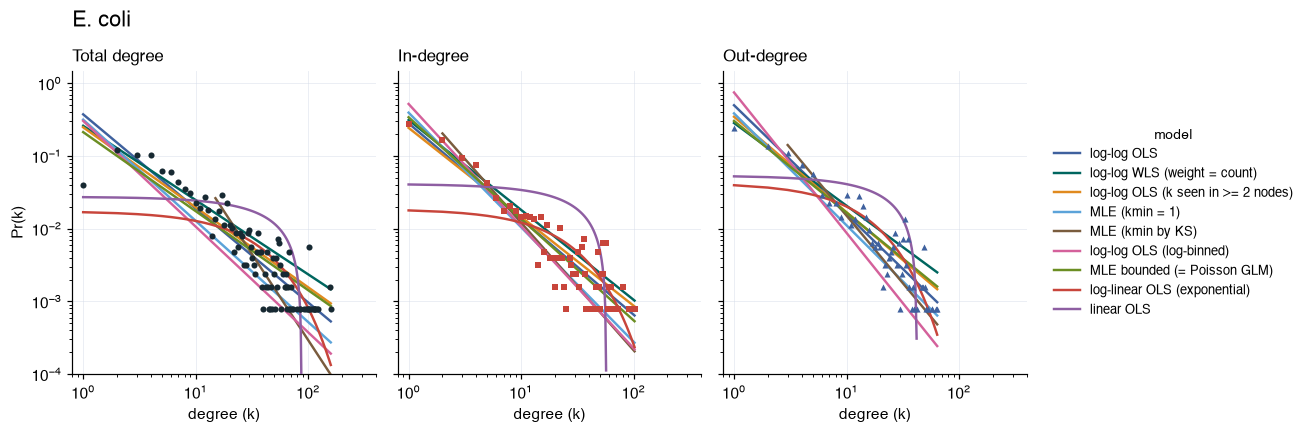

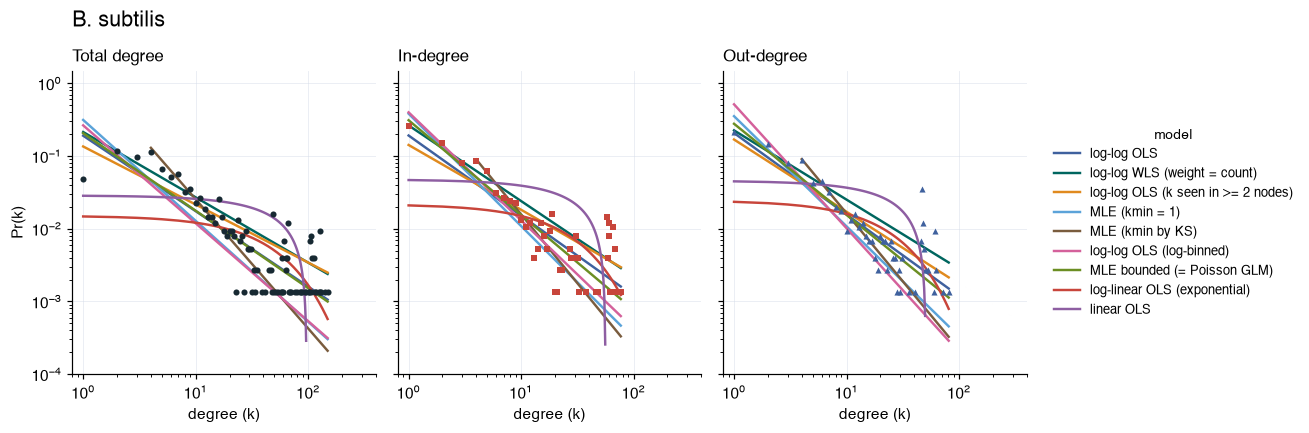

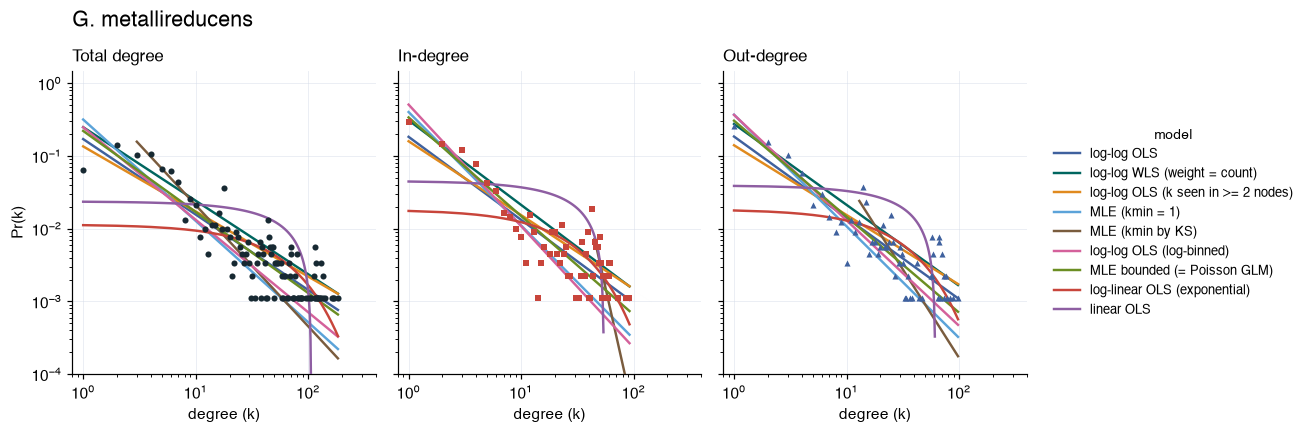

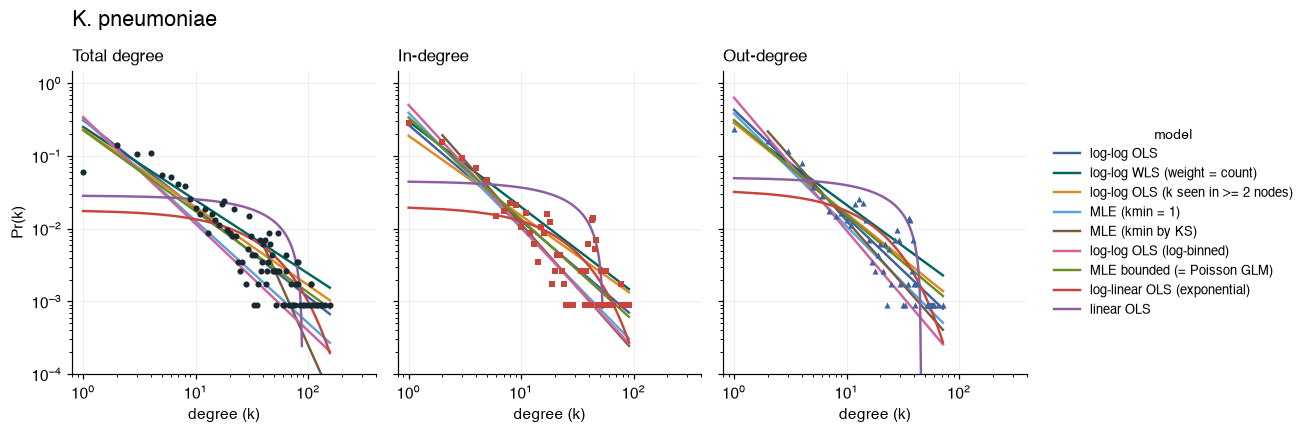

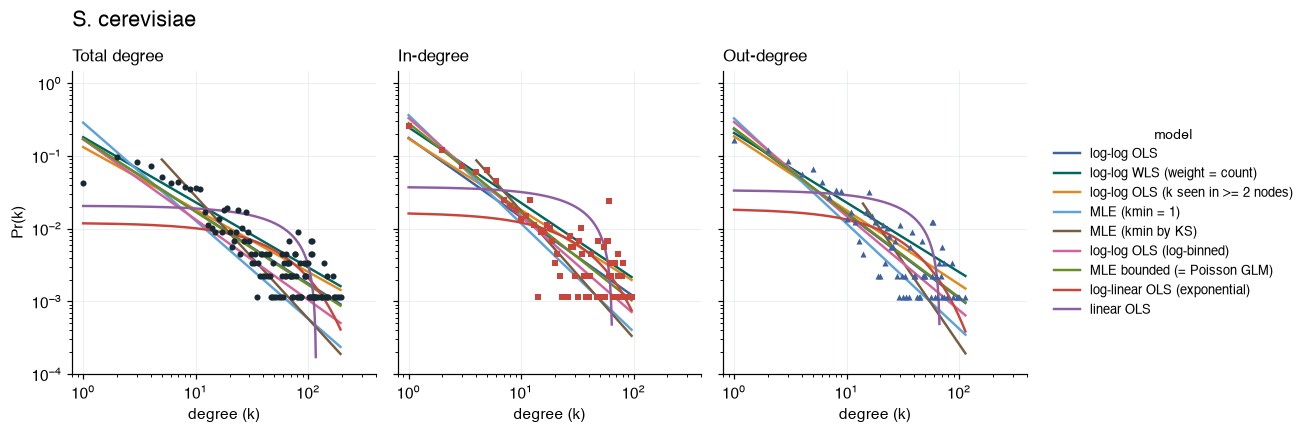

In [19]:
for k in data.KEYS:
    P.fits_by_model(k, sup_deg[k], FIG / f"10_{k}_fits_by_model.png"); plt.show()

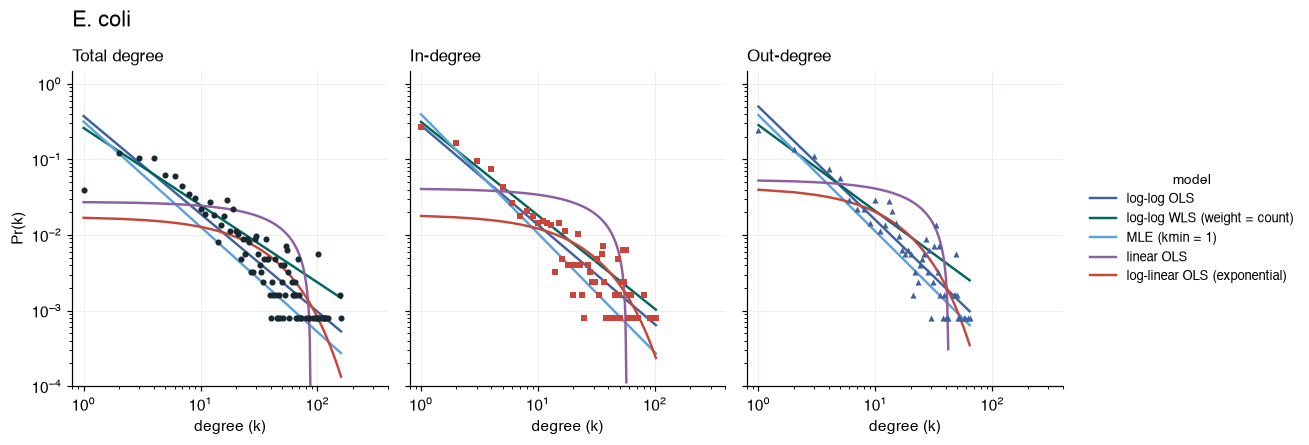

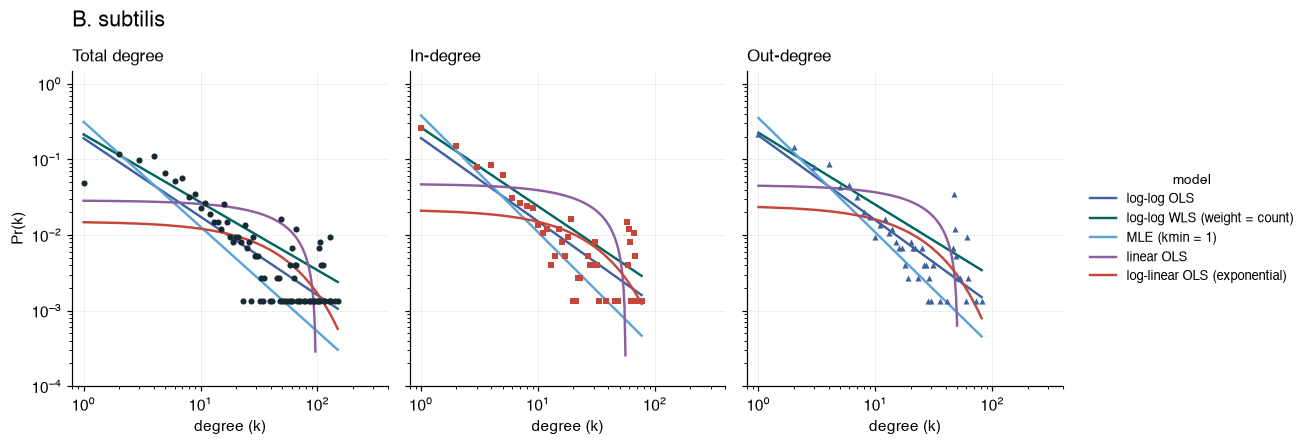

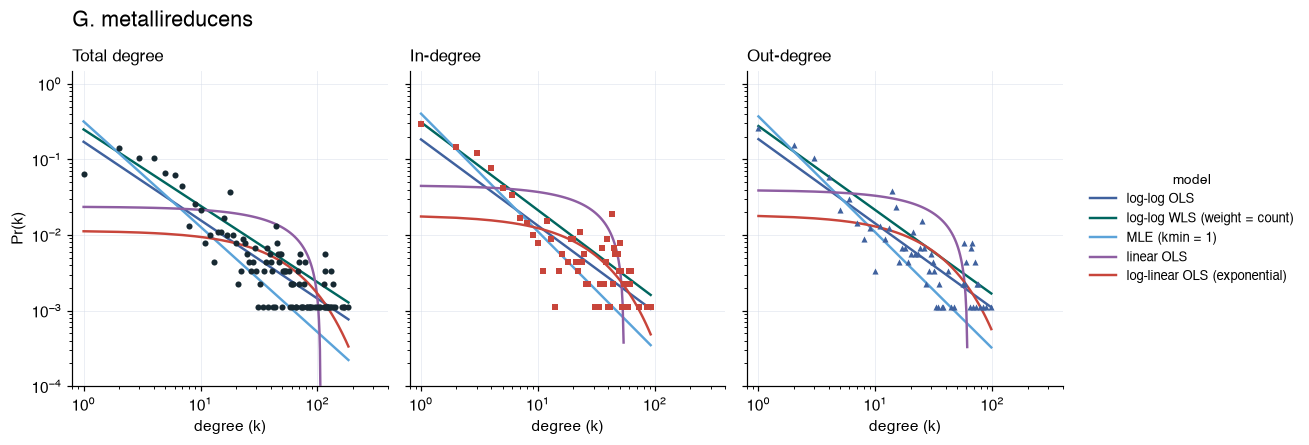

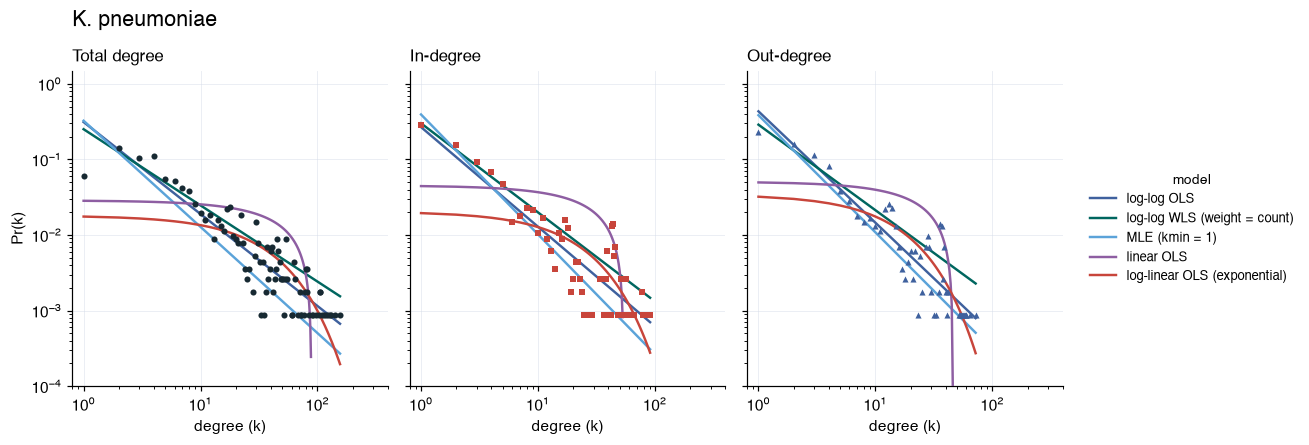

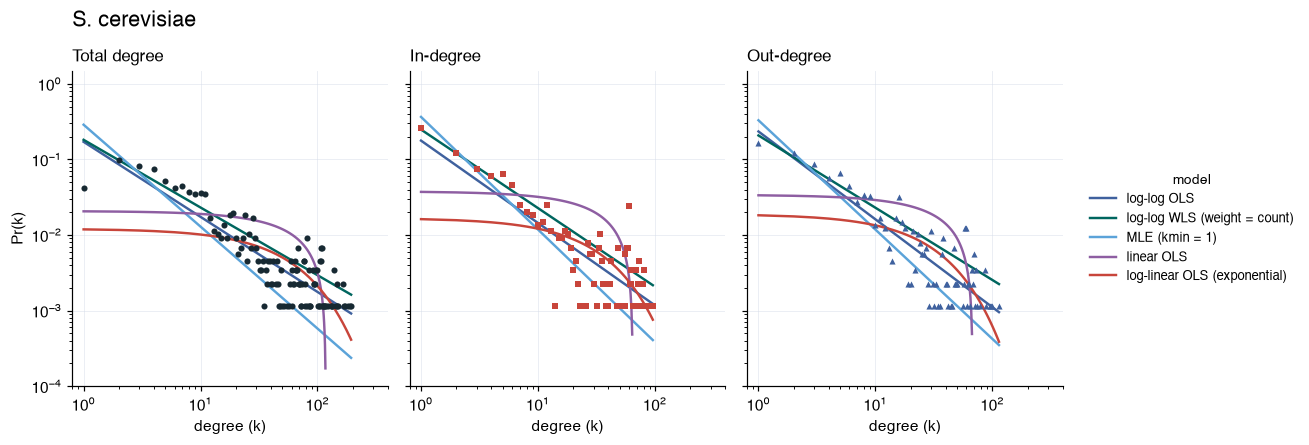

In [20]:
for k in data.KEYS:
    P.fits_by_model(k, sup_deg[k], FIG / f"10_{k}_fits_by_model_core.png", methods=P.CORE_METHODS); plt.show()

### 4.3 What method was best? Exponent simulation
We simulate networks with a **known** exponent (n = 1000 nodes; degrees from a power law on 1…k_max; 300 replicates per setting), ask every method to estimate it, and measure the bias.

- The paper-style OLS is **biased low** (slope too shallow) — by about 0.5–1.0 here — even when the data are exactly a power law; the other methods are much closer.
- Why: at the high-connection end most degrees are empty because very few reactions have that many connections. Every degree seen once sits at the same floor, Pr = 1/n, which flattens the tail and drags the OLS line toward zero slope (left panel).
- MLE (kmin = 1) and the bounded MLE/Poisson fit are essentially unbiased (|bias| ≲ 0.05).

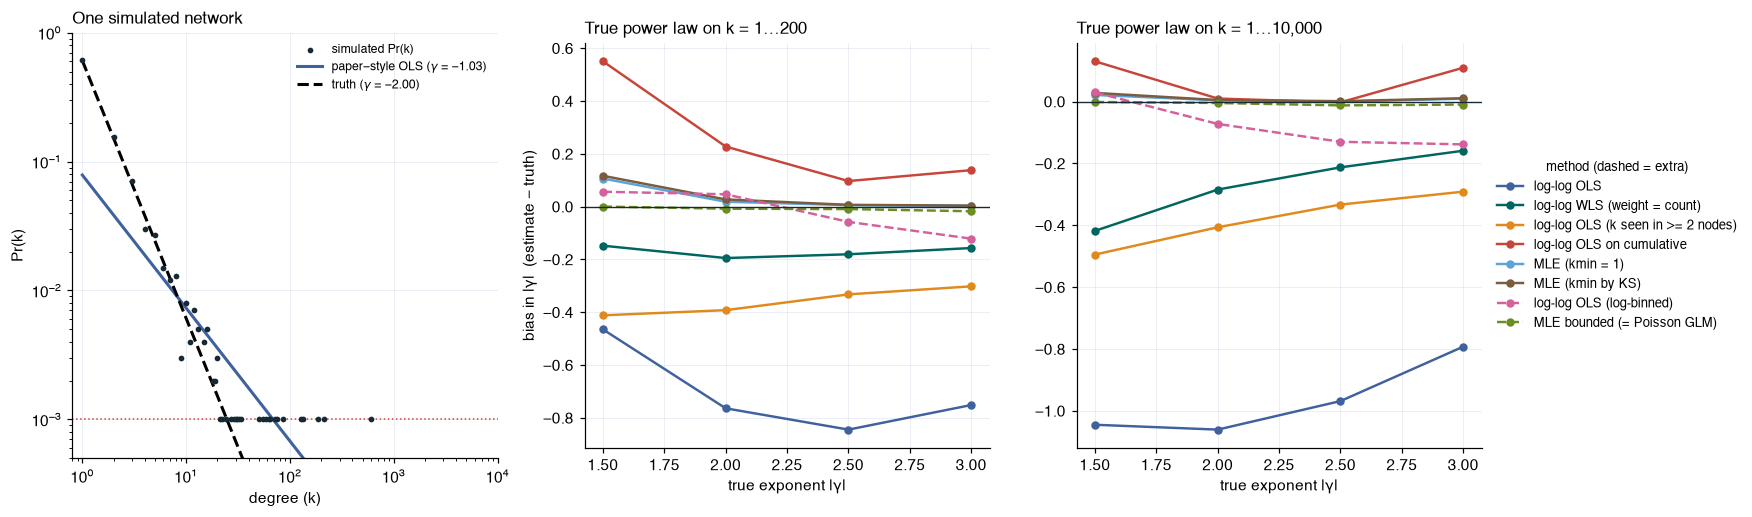

kmax                               200                     10000                  
true                                 1.5   2.0   2.5   3.0   1.5   2.0   2.5   3.0
method                                                                            
log-log OLS                        -0.47 -0.76 -0.84 -0.75 -1.04 -1.06 -0.97 -0.79
log-log WLS (weight = count)       -0.15 -0.19 -0.18 -0.16 -0.42 -0.28 -0.21 -0.16
log-log OLS (k seen in >= 2 nodes) -0.41 -0.39 -0.33 -0.30 -0.49 -0.41 -0.33 -0.29
log-log OLS on cumulative           0.55  0.23  0.10  0.14  0.13  0.01 -0.00  0.11
MLE (kmin = 1)                      0.11  0.02  0.01  0.00  0.02  0.00 -0.00  0.01
MLE (kmin by KS)                    0.12  0.03  0.01  0.00  0.03  0.00  0.00  0.01
log-log OLS (log-binned)            0.06  0.05 -0.06 -0.12  0.03 -0.07 -0.13 -0.14
MLE bounded (= Poisson GLM)         0.00 -0.01 -0.01 -0.02 -0.00 -0.00 -0.01 -0.01

Paper-style OLS bias ranges from **-1.06 to -0.47** across settings; the bounded MLE (= Poisson) ranges -0.02 to +0.00; MLE (kmin = 1) -0.00 to +0.11.

In [21]:
sim = S.run(n=1000, reps=300, alphas=(1.5, 2.0, 2.5, 3.0), kmaxes=(200, 10000), seed=1)
sim.to_csv(RES / "08_simulation_bias.csv", index=False)
P.simulation_figure(sim, S.example(n=1000, alpha=2.0, kmax=10000), 2.0, FIG / "11_simulation_bias.png"); plt.show()
bias = sim.pivot_table(index="method", columns=["kmax", "true"], values="bias").loc[list(R.ESTIMATORS)]
display(bias.round(2))
ols_b = sim[sim.method == "log-log OLS"].bias
display(Markdown(f"Paper-style OLS bias ranges from **{ols_b.min():.2f} to {ols_b.max():.2f}** across settings; the bounded MLE (= Poisson) ranges "
                 f"{sim[sim.method.str.startswith('MLE bounded')].bias.min():+.2f} to {sim[sim.method.str.startswith('MLE bounded')].bias.max():+.2f}; MLE (kmin = 1) "
                 f"{sim[sim.method=='MLE (kmin = 1)'].bias.min():+.2f} to {sim[sim.method=='MLE (kmin = 1)'].bias.max():+.2f}."))

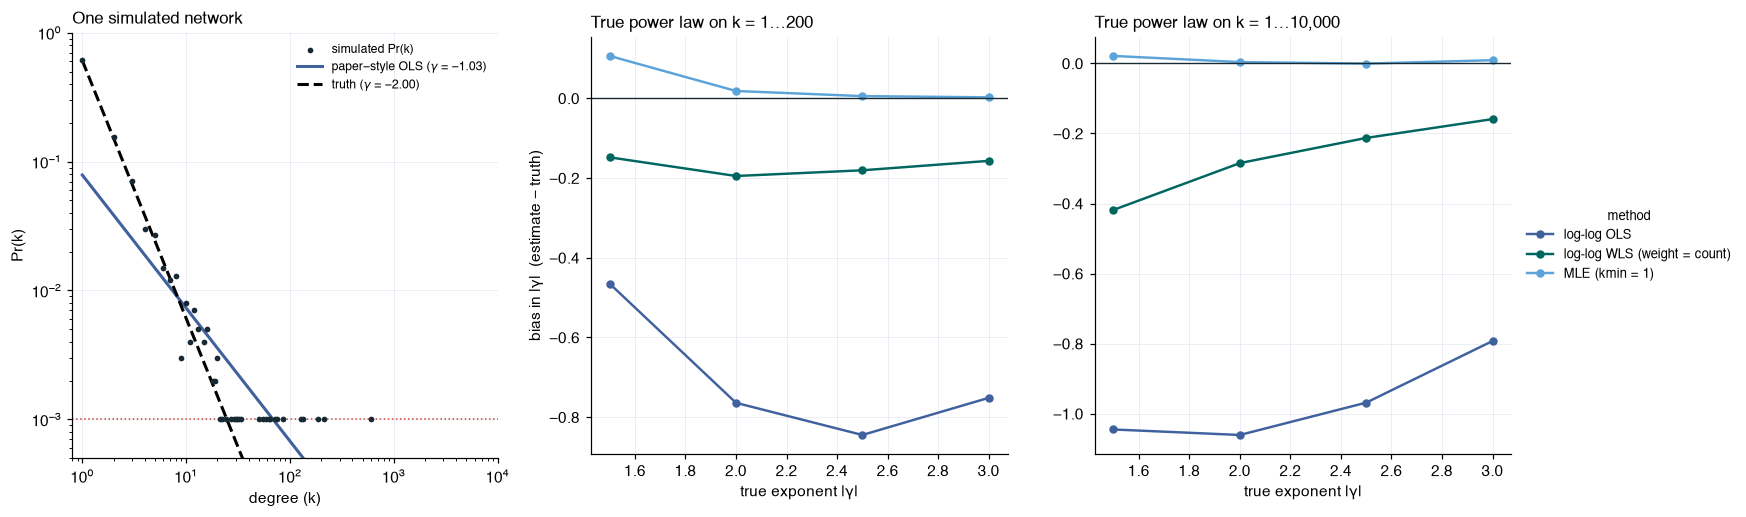

In [22]:
# core-method versions (log-log OLS, log-log WLS, MLE kmin = 1, linear, log-linear)
P.simulation_figure(sim, S.example(n=1000, alpha=2.0, kmax=10000), 2.0, FIG / "11_simulation_bias_core.png", methods=P.CORE_METHODS); plt.show()